# M13 mini-lab — Train/validation/test splits & cross-validation

In this notebook you'll practice **splitting data properly** and using **cross-validation**
to estimate and improve model performance.

We'll work with a synthetic **credit card fraud** dataset:

- Each row is a past transaction with engineered features.
- The target `is_fraud` is 1 for fraudulent transactions, 0 otherwise.
- A fraud analytics team will use your model to **prioritize transactions for investigation**.

There are two small interactive experiments using **plotly**:
1. How much does a random train/test split matter?
2. How does the distribution of CV scores change with the number of folds $K$?


## 0. Setup

In [1]:
# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import plotly.express as px

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, classification_report

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


In [2]:
# 1. Generate a small synthetic fraud dataset

n_samples = 1500

X, y = make_classification(
    n_samples=n_samples,
    n_features=6,
    n_informative=4,
    n_redundant=1,
    n_repeated=0,
    n_clusters_per_class=2,
    weights=[0.96, 0.04],  # ~4% fraud
    flip_y=0.01,
    random_state=RANDOM_STATE,
)

feature_names = [
    "amount",
    "days_since_last_tx",
    "card_age_months",
    "merchant_risk_score",
    "hour_of_day",
    "device_trust_score",
]

df = pd.DataFrame(X, columns=feature_names)
df["is_fraud"] = y

print(df.head())
print("\nClass balance:")
print(df["is_fraud"].value_counts(normalize=True).rename("proportion"))

assert len(df) == n_samples


     amount  days_since_last_tx  card_age_months  merchant_risk_score  \
0 -0.234373            1.004242        -0.386695            -0.862743   
1  0.918796           -0.262210         1.302603             2.873578   
2  0.526696            0.524000        -1.071553             0.197359   
3  0.232798            0.205568         0.196695             0.799942   
4  0.630113           -1.031392         0.017419            -0.549819   

   hour_of_day  device_trust_score  is_fraud  
0    -0.032917           -0.140448         0  
1    -3.560945           -0.354622         0  
2     0.052271           -1.531038         0  
3    -0.488831           -0.099855         0  
4    -1.360607           -1.313415         0  

Class balance:
is_fraud
0    0.958
1    0.042
Name: proportion, dtype: float64


## 1. Core Task — Basic train/test split

**Goal:** Compare training and test performance for a simple baseline model.

We'll start with a standard **80/20 stratified train/test split** and a logistic regression classifier.


In [3]:
# TODO 1: Basic stratified 80/20 train/test split

X = df[feature_names].values
y = df["is_fraud"].values

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,          # try removing this to see what happens
    random_state=RANDOM_STATE,
)

print("Train size:", X_train.shape[0])
print("Test size: ", X_test.shape[0])

print("\nTrain fraud rate: {:.3f}".format(y_train.mean()))
print("Test fraud rate:  {:.3f}".format(y_test.mean()))

assert X_train.shape[0] + X_test.shape[0] == X.shape[0]


Train size: 1200
Test size:  300

Train fraud rate: 0.042
Test fraud rate:  0.043


In [4]:
# Fit a simple baseline model and compare train vs test metrics

baseline_clf = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

baseline_clf.fit(X_train, y_train)

y_train_pred = baseline_clf.predict(X_train)
y_test_pred = baseline_clf.predict(X_test)

print("Train accuracy: {:.3f}".format(accuracy_score(y_train, y_train_pred)))
print("Test  accuracy: {:.3f}".format(accuracy_score(y_test, y_test_pred)))
print("Test  recall:   {:.3f}".format(recall_score(y_test, y_test_pred)))

assert 0.0 <= recall_score(y_test, y_test_pred) <= 1.0


Train accuracy: 0.959
Test  accuracy: 0.960
Test  recall:   0.077


### Class balance check

If stratification worked, the positive-class fraction should be similar in train and test.

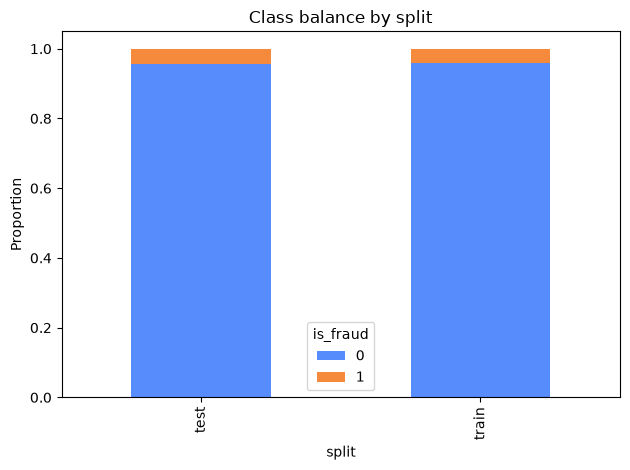

In [5]:
split_labels = ["train"] * len(y_train) + ["test"] * len(y_test)
y_all = np.concatenate([y_train, y_test])

balance_df = pd.DataFrame({
    "split": split_labels,
    "is_fraud": y_all,
})

class_counts = (
    balance_df
    .groupby(["split", "is_fraud"])
    .size()
    .reset_index(name="count")
)

pivot = class_counts.pivot(index="split", columns="is_fraud", values="count")
pivot = pivot.div(pivot.sum(axis=1), axis=0)

pivot.plot(kind="bar", stacked=True)
plt.ylabel("Proportion")
plt.title("Class balance by split")
plt.legend(title="is_fraud", loc="best")
plt.tight_layout()
plt.show()


## 2. Experiment A — How much does a random split matter?

Here we repeatedly re-split the same data into train/test with different seeds and
test-set sizes, and track the resulting **test recall**.

- Try changing `test_sizes` and the number of seeds.
- Notice how variability changes: when would you trust a single split?


In [6]:
test_sizes = [0.1, 0.2, 0.3, 0.4]  # TODO: try different values

rows = []

for t in test_sizes:
    for seed in range(100):  # TODO: try fewer or more seeds
        X_train_tmp, X_test_tmp, y_train_tmp, y_test_tmp = train_test_split(
            X, y, test_size=t, stratify=y, random_state=seed
        )
        tmp_model = Pipeline([
            ("scaler", StandardScaler()),
            ("logreg", LogisticRegression(max_iter=1000, random_state=seed)),
        ])
        tmp_model.fit(X_train_tmp, y_train_tmp)
        y_pred_tmp = tmp_model.predict(X_test_tmp)
        rec = recall_score(y_test_tmp, y_pred_tmp)
        rows.append({"test_size": t, "seed": seed, "test_recall": rec})

split_df = pd.DataFrame(rows)

fig = px.box(
    split_df,
    x="test_size",
    y="test_recall",
    points="all",
    labels={"test_size": "Test size proportion", "test_recall": "Test recall"},
    title="How much does test recall vary across random splits?"
)
fig


ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'alignmentgroup': 'True',
              'boxpoints': 'all',
              'hovertemplate': 'Test size proportion=%{x}<br>Test recall=%{y}<extra></extra>',
              'legendgroup': '',
              'marker': {'color': '#636efa'},
              'name': '',
              'notched': False,
              'offsetgroup': '',
              'orientation': 'v',
              'showlegend': False,
              'type': 'box',
              'x': {'bdata': ('mpmZmZmZuT+amZmZmZm5P5qZmZmZmb' ... 'mZmZnZP5qZmZmZmdk/mpmZmZmZ2T8='),
                    'dtype': 'f8'},
              'x0': ' ',
              'xaxis': 'x',
              'y': {'bdata': ('AAAAAAAAAAAAAAAAAAAAAAAAAAAAAA' ... '5H4XqkP3sUrkfherQ/uB6F61G4vj8='),
                    'dtype': 'f8'},
              'y0': ' ',
              'yaxis': 'y'}],
    'layout': {'boxmode': 'group',
               'legend': {'tracegroupgap': 0},
               'template': '...',
               'title': {'text': 'How much does test recall vary across random splits?'},
               'xaxis': {'anchor': 'y', 'domain': [0.0, 1.0], 'title': {'text': 'Test size proportion'}},
               'yaxis': {'anchor': 'x', 'domain': [0.0, 1.0], 'title': {'text': 'Test recall'}}}
})

**Questions:**

- At which test size does recall seem most stable?

  **The 30% test size appears most stable for the middle half of the scores because it has the narrowest box. However, 40% has fewer extreme results and the smallest overall range.**

- Would you be comfortable reporting a single-split test recall at `test_size=0.1`? Why or why not?

  **No, because recall varies from 0% to 50% across splits. The small test set contains very few fraud cases, so catching or missing one case changes recall a lot**.


## 3. Core Task — Train/validation/test split & model selection

Now we add a validation set for hyperparameter tuning.

Plan:
1. Split data into **train_val** and **test**.
2. Split train_val into **train** and **validation**.
3. Use validation recall to choose regularization strength `C`.
4. Train on train_val and evaluate once on the held-out test set.


In [ ]:
# Create train, validation, and test splits

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE,
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.25,  # 0.25 of 0.8 => 0.2 of full data
    stratify=y_train_val,
    random_state=RANDOM_STATE,
)

print("Train size:     ", X_train.shape[0])
print("Validation size:", X_val.shape[0])
print("Test size:      ", X_test.shape[0])

assert X_train.shape[0] + X_val.shape[0] + X_test.shape[0] == X.shape[0]


In [ ]:
def make_model(C):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("logreg", LogisticRegression(C=C, max_iter=1000, random_state=RANDOM_STATE)),
    ])

Cs = [0.1, 1.0, 10.0]  # TODO: add more values

results = []

for C in Cs:
    model = make_model(C)
    model.fit(X_train, y_train)
    y_val_pred = model.predict(X_val)
    acc = accuracy_score(y_val, y_val_pred)
    rec = recall_score(y_val, y_val_pred)
    results.append({"C": C, "val_accuracy": acc, "val_recall": rec})

val_results = pd.DataFrame(results)
print(val_results)

best_idx = val_results["val_recall"].idxmax()
best_C = val_results.loc[best_idx, "C"]
print("\nBest C by validation recall:", best_C)

assert best_C in Cs


In [ ]:
# Train on train_val and evaluate once on the test set

best_model = make_model(best_C)
best_model.fit(X_train_val, y_train_val)

y_test_pred = best_model.predict(X_test)

print("Classification report on test set:")
print(classification_report(y_test, y_test_pred, digits=3))

test_recall = recall_score(y_test, y_test_pred)
print("Test recall: {:.3f}".format(test_recall))

assert 0.0 <= test_recall <= 1.0


## 4. Core Task — k-fold cross-validation

Now we use **stratified k-fold cross-validation** on the train_val data
to get a more stable performance estimate for each `C`.


In [ ]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

Cs_cv = [0.01, 0.1, 1.0, 10.0]

cv_rows = []

for C in Cs_cv:
    model = make_model(C)
    scores = cross_val_score(
        model,
        X_train_val,
        y_train_val,
        cv=skf,
        scoring="recall",
        n_jobs=None,
    )
    cv_rows.append({
        "C": C,
        "mean_recall": scores.mean(),
        "std_recall": scores.std(),
    })

cv_df = pd.DataFrame(cv_rows).sort_values("C")
print(cv_df)


In [ ]:
plt.errorbar(cv_df["C"], cv_df["mean_recall"], yerr=cv_df["std_recall"], fmt="-o")
plt.xscale("log")
plt.xlabel("C (log scale)")
plt.ylabel("Mean CV recall")
plt.title("Stratified 5-fold CV on train_val data")
plt.tight_layout()
plt.show()


## 5. Experiment B — CV scores as a function of K

Here we keep a fixed `C` (the best one you found) and vary
the number of folds $K$ in stratified k-fold CV.

Questions to keep in mind:
- Does the mean recall change a lot with $K$?
- How does the **spread** of fold scores change with $K$?


In [ ]:
Ks = [3, 5, 10, 20, 40]  # TODO: add/remove values

rows = []

for K in Ks:
    skf_tmp = StratifiedKFold(
        n_splits=K,
        shuffle=True,
        random_state=RANDOM_STATE,
    )
    scores = cross_val_score(
        make_model(best_C),
        X_train_val,
        y_train_val,
        cv=skf_tmp,
        scoring="recall",
        n_jobs=None,
    )
    for s in scores:
        rows.append({"K": K, "fold_recall": s})

cv_k_df = pd.DataFrame(rows)

fig = px.violin(
    cv_k_df,
    x="K",
    y="fold_recall",
    box=True,
    points="all",
    labels={"K": "Number of folds K", "fold_recall": "Fold recall"},
    title="Cross-validation recall distribution vs number of folds",
)
fig


**Questions:**

- For this dataset, which K would you choose and why?

  **I would choose K = 3 because it has the smallest spread of fold recall scores in this experiment and more fraud cases per validation fold.**
- If compute were extremely cheap, would you always choose a very large K?

  **No. At K = 40, recall ranges from 0% to 100% because each fold contains very few fraud cases. A large K can make individual fold scores unstable, even when computation is cheap.**


## 6. Reflection

Use this space to jot down brief answers (bullets are fine):

- Which split / CV configuration gave you the most confidence in the model's performance, and why?

  **Stratified 3-fold CV gave me the most confidence of the settings that I tested because there was less variance in fold recall and there were more frauds per validation fold. Even then, recall was low enough to miss most frauds.**
  
- Where could **data leakage** sneak into the workflows you used here?

  **Leakage could have occurred in case of scaling all the data prior to splitting or using the test data to decide on the model parameters. The pipeline avoids leakage in scaling since the scaler is fitted on the training subset only.**

- If you had **10× more data**, how would you change your splitting / CV strategy?

  **I would keep a separate stratified test set and use 5-fold CV for tuning. More data would provide more fraud cases per fold, making recall less sensitive to individual predictions.**

- Which assumption about the data (IID, stationarity, label quality, etc.) do you **trust less** now than before?

   **I would wonder about whether previous transactions predict future transactions, as it is possible that the fraud patterns change through time. This synthetic example does not address this problem.**
